In [ ]:
# Урок 31 Уровень значимости

In [10]:
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

In [1]:
0.0225 < 0.05

True

In [2]:
0.0225 < 0.02

False

In [ ]:
# Урок 32 Центральная предельная теорема

In [ ]:
np.random.seed(105)
random_data = (np.random.random(1000) * 100).tolist() + np.random.exponential(5,200).tolist() + np.random.normal(80, 20, 500).tolist()

In [7]:
np.mean(random_data)

54.77171853691253

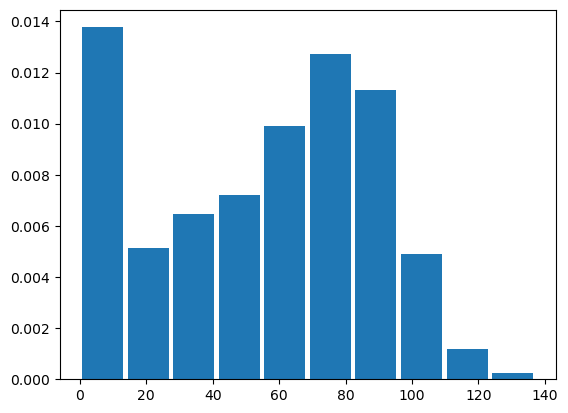

In [8]:
plt.hist(random_data, rwidth=0.9,density=True)
plt.show()

In [15]:
len(random_data)

1700

In [16]:
sample_data = np.random.choice(random_data, 100)
np.mean(sample_data)

52.83893716589601

In [20]:
collected_means =[]

for i in range(1000):
    sample_data = np.random.choice(random_data, 100)
    sample_mean = np.mean(sample_data)
    collected_means.append(sample_mean)

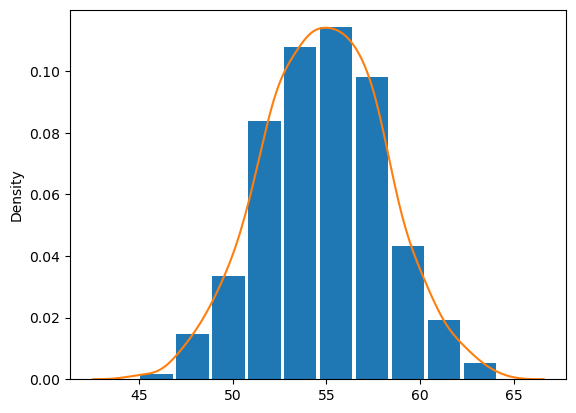

In [21]:
plt.hist(collected_means, rwidth=0.9, density=True)
sns.kdeplot(collected_means)
plt.show()

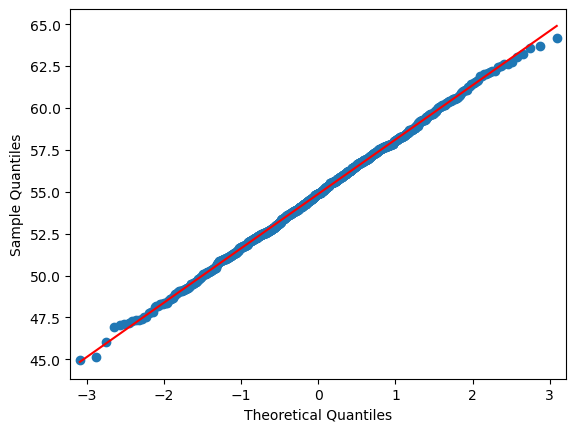

In [22]:
sm.qqplot(np.array(collected_means), line='r')
plt.show()

In [23]:
np.mean(collected_means), np.mean(random_data)

(54.868161090480015, 54.77171853691253)

In [24]:
np.std(collected_means), np.std(sample_data)/np.sqrt(100)

(3.2254436853740818, 3.321668785136828)

In [ ]:
# Урок 33 Пример задачи

In [25]:
np.random.seed(105)
city_ages = [np.floor(i) for i in np.random.uniform(10, 80, 100000)]
sample_ages = np.random.choice(city_ages, 100)

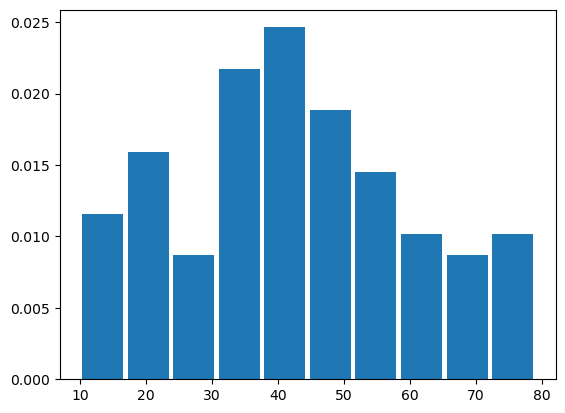

In [26]:
plt.hist(sample_ages, density=True, rwidth=0.9)
plt.show()

In [27]:
sample_mean = np.mean(sample_ages)
sample_std = np.std(sample_ages, ddof=1)

norm_dist_std= sample_std/np.sqrt(100)

In [28]:
norm_dist_std, sample_mean

(1.8011118900290566, 41.94)

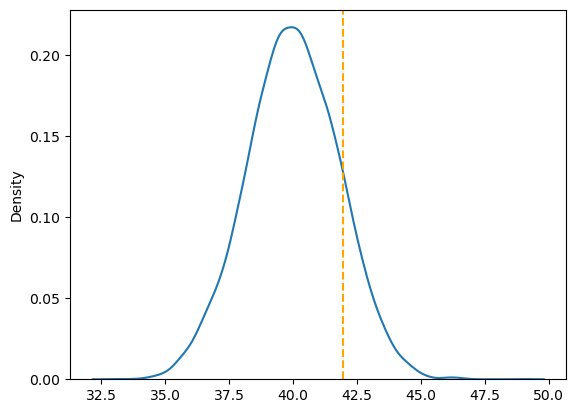

In [29]:
np.random.seed(105)
demonstration_list = np.random.normal(40, norm_dist_std, 10000)
sns.kdeplot(demonstration_list)
plt.axvline(sample_mean, linestyle='--', color ='orange')
plt.show()

In [35]:
from scipy.stats import norm
mean = 0
std_dev =1 

threshold =0.91

In [37]:
mean = 40
std_dev = norm_dist_std

threshold = sample_mean

probability = 1 - norm.cdf(threshold, loc=mean, scale=std_dev)

print(f'Шанс получить выборку со средним значением {threshold} и выше составляет: {probability:.4f}')

Шанс получить выборку со средним значением 41.94 и выше составляет: 0.1407


In [ ]:
# Урок 34 Доверительный интервал

In [38]:
np.random.seed(105)
trivial_example = np.random.normal(100, 5, 1000)

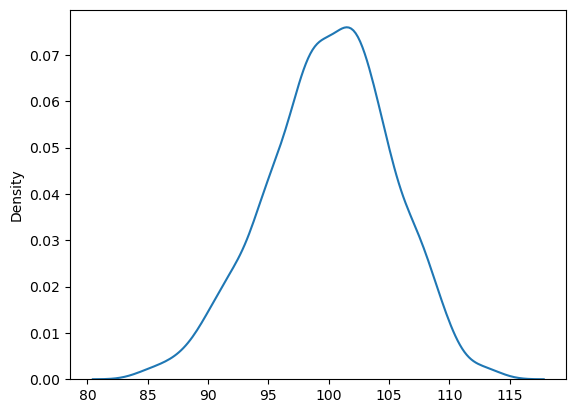

In [39]:
sns.kdeplot(trivial_example)
plt.show()

In [45]:
import pandas as pd
import numpy as np
import random as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy.stats import norm
from scipy.stats import t

In [47]:
ul = norm.ppf(0.975, 100, 5)
ll = norm.ppf(0.025, 100, 5)
(ul, ll)

(109.79981992270027, 90.20018007729973)

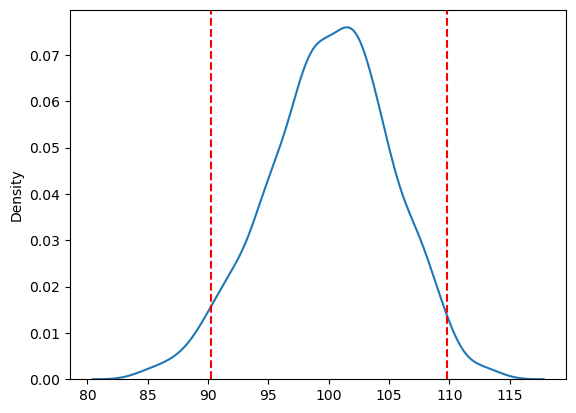

In [48]:
sns.kdeplot(trivial_example)
plt.axvline(ul, linestyle='--', color ='red')
plt.axvline(ll, linestyle='--', color ='red')
plt.show()

In [ ]:
# Урок 35 Точечная оценка

In [52]:
np.random.seed(105)
travel_time = np.random.gamma(150, 0.2, 50)

In [53]:
norm_dist_std = np.std(travel_time, ddof=1)/ np.sqrt(len(travel_time))
mean = np.mean(travel_time)
print(norm_dist_std, mean)

0.4363269669643673 30.18779052050835


In [54]:
# точечная оценка
np.mean(travel_time)

30.18779052050835

In [56]:
# точечная оценка
np.median(travel_time)

29.84986114689545

In [ ]:
# Урок 36 Задача на доверительный интервал

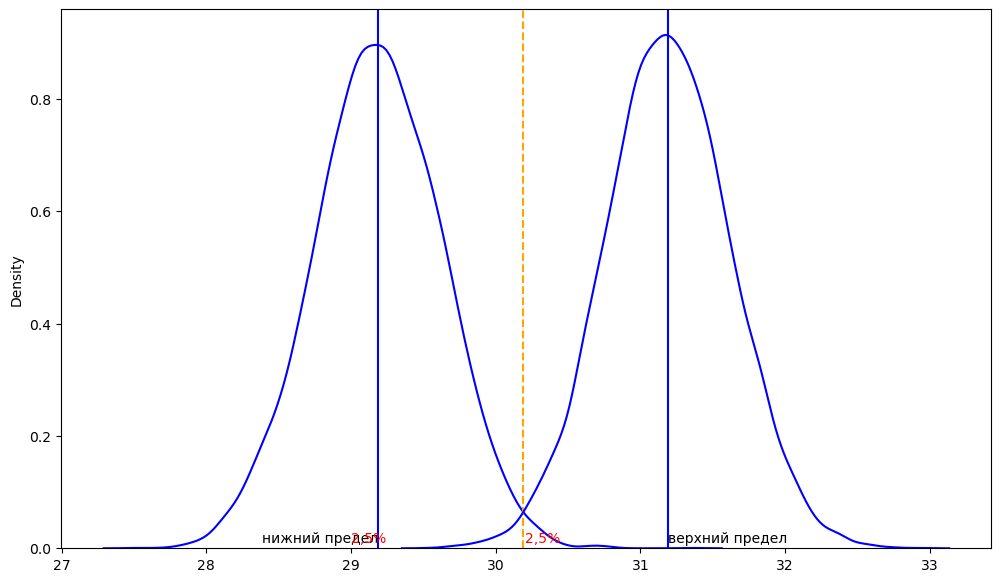

In [65]:
np.random.seed(105)
plt.figure(figsize=(12,7))
demonstration_list1 = np.random.normal(mean-1, norm_dist_std, 10000)
demonstration_list2 = np.random.normal(mean+1, norm_dist_std, 10000)

sns.kdeplot(demonstration_list1, color='blue')

plt.axvline(mean, linestyle='--', color ='orange')
plt.axvline(mean-1, linestyle='-', color ='blue')
plt.text(30.2, 0.01, '2,5%', fontsize=10, color='red')
plt.text(mean-1.8,0.01,'нижний предел', fontsize=10, color='black')

sns.kdeplot(demonstration_list2, color='blue')
plt.axvline(mean+1, linestyle='-', color ='blue')
plt.text(29, 0.01, '2,5%', fontsize=10, color='red')
plt.text(mean+1, 0.01,'верхний предел', fontsize=10, color='black')

plt.show()

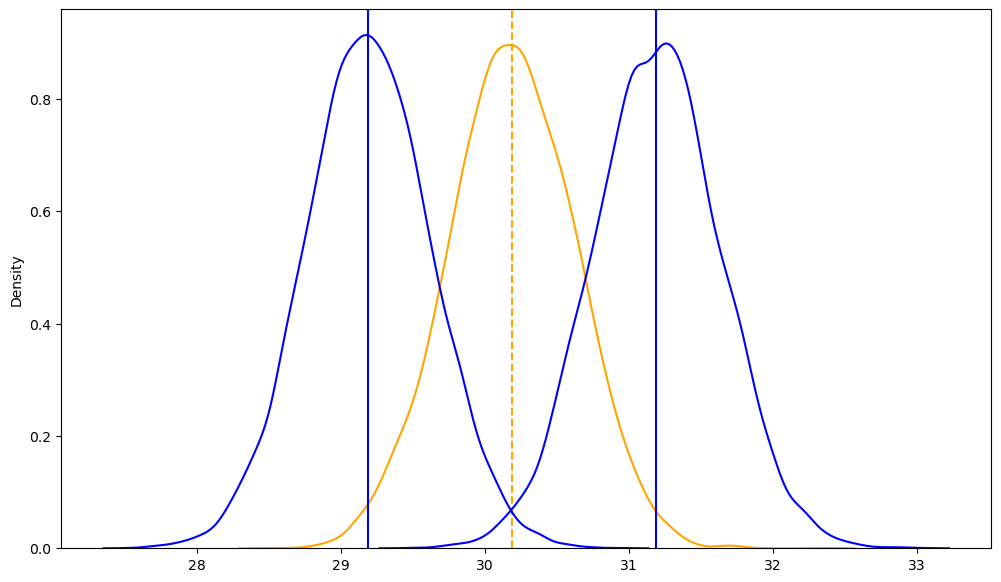

In [66]:
np.random.seed(105)
plt.figure(figsize=(12,7))
demonstration_list = np.random.normal(mean, norm_dist_std, 10000)
demonstration_list1 = np.random.normal(mean-1, norm_dist_std, 10000)
demonstration_list2 = np.random.normal(mean+1, norm_dist_std, 10000)

sns.kdeplot(demonstration_list, color='orange')
plt.axvline(mean, linestyle='--', color ='orange')

sns.kdeplot(demonstration_list1, color='blue')
plt.axvline(mean-1, linestyle='-', color ='blue')

sns.kdeplot(demonstration_list2, color='blue')
plt.axvline(mean+1, linestyle='-', color ='blue')

plt.show()

In [67]:
# доверительный интервал
ul = norm.ppf(0.975, mean, norm_dist_std)
ll = norm.ppf(0.025, mean, norm_dist_std)
print(ul, ll)

31.04297566124211 29.33260537977459


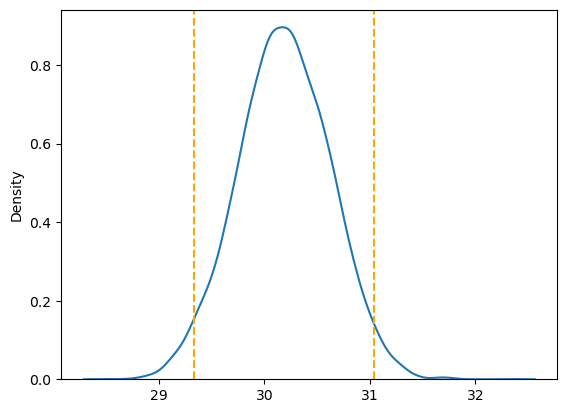

In [70]:
np.random.seed(105)
demonstration_list = np.random.normal(mean, norm_dist_std, 10000)
sns.kdeplot(demonstration_list)
plt.axvline(ul, linestyle='--', color ='orange')
plt.axvline(ll, linestyle='--', color ='orange')
plt.show()

In [ ]:
# Урок 37 t - распределение

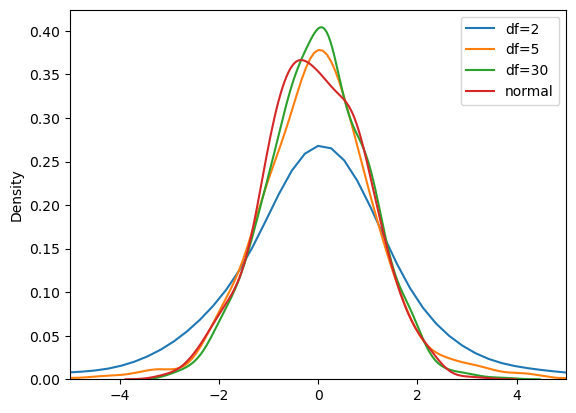

In [71]:
np.random.seed(105)

student1 = np.random.standard_t(2, 1000)
student5 = np.random.standard_t(5, 1000)
student30 = np.random.standard_t(30, 1000)
st_normal = np.random.standard_normal(1000)

sns.kdeplot(student1, label='df=2')
sns.kdeplot(student5, label='df=5')
sns.kdeplot(student30, label='df=30')
sns.kdeplot(st_normal, label='normal')
plt.legend()
plt.xlim(-5, 5)
plt.show()

In [72]:
from scipy.stats import t

In [73]:
t.cdf(25, 30, 30, 5)

0.16265430771301492

In [75]:
t.ppf(0.975, 25, 39, 5),t.ppf(0.025, 25, 30, 5)

(49.29769276376647, 19.702307236233526)

In [ ]:
# Урок 38 Пример на t- распределение

In [76]:
np.random.seed(105)
travel_time = np.random.gamma(150, 0.2, 10)

In [78]:
t_dist_std = np.std(travel_time, ddof=1/ np.sqrt(len(travel_time)))
mean = np.mean(travel_time)
dof = len(travel_time) - 1
print(t_dist_std, mean, dof)

1.4970283491478498 29.981016408235888 9


In [79]:
# Точечная оценка
np.mean(travel_time)

29.981016408235888

In [80]:
# Точечная оценка
np.median(travel_time)

29.528064121642515

In [83]:
# доверительный интервал
ul = t.ppf(0.975, dof, mean, t_dist_std)
ll = t.ppf(0.025, dof,  mean, t_dist_std)
print(ul, ll)

33.36752981108702 26.59450300538476


In [ ]:
# Урок 39 Тестирование гипотез

In [85]:
import pandas as pd
import numpy as np
import random as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy.stats import norm
from scipy.stats import t

In [93]:
np.random.seed(105)
ages = np.random.gamma(160, 0.5, 20)

In [94]:
mean = np.mean(ages)
std = np.std(ages, ddof=1)
size = len(ages)
dof = size - 1
mean_err = std/ np.sqrt(size)

In [95]:
t_stat = (mean - 79) / mean_err
print(t_stat)

1.6087525940460243


In [96]:
1 - t.cdf(t_stat, dof)

0.0620802533569379

In [97]:
t5, t95, t90 = t.ppf([0.05, 0.95, 0.9], dof)
t5, t95, t90

(-1.7291328115213678, 1.729132811521367, 1.3277282090267986)

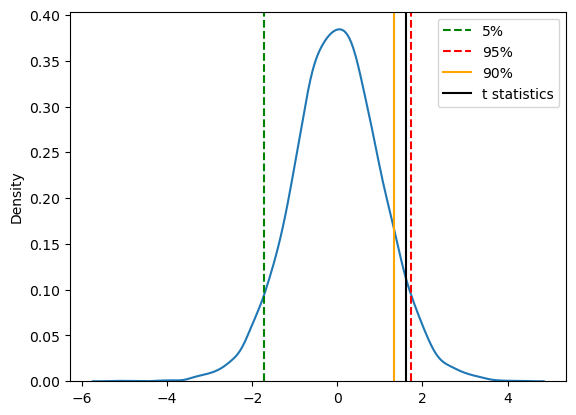

In [99]:
np.random.seed(105)
demonstration_data = np.random.standard_t(dof,10000)
sns.kdeplot(demonstration_data)
plt.axvline(t5, linestyle='--', label ='5%', color ='green')
plt.axvline(t95, linestyle='--', label ='95%', color ='red')


plt.axvline(t90, linestyle='-', label='90%', color ='orange')
plt.axvline(t_stat, linestyle='-', label='t statistics', color ='black')

plt.legend()
plt.show()

In [ ]:
# Урок 40 Выборка vs выборка; one tail

In [100]:
np.random.seed(105)
olds = np.random.normal(1000, 30, 100)
news = np.random.normal(965, 100, 100)

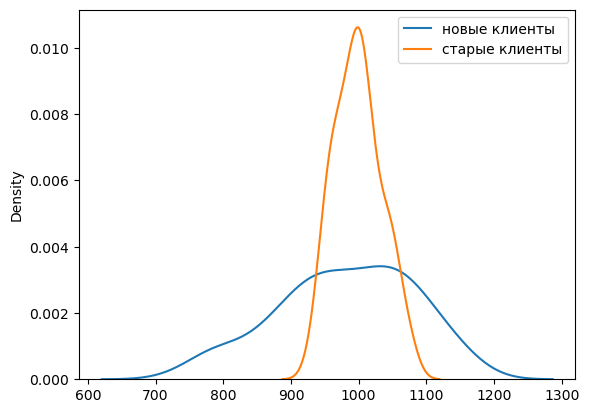

In [101]:
sns.kdeplot(news, label='новые клиенты')
sns.kdeplot(olds, label='старые клиенты')
plt.legend()
plt.show()

In [102]:
olds_mean = np.mean(olds)
news_mean = np.mean(news)

olds_std = np.std(olds, ddof=1)
news_std = np.std(news, ddof=1)

olds_size = len(olds)
news_size = len(news)

dof = olds_size + news_size - 2

err_diff = np.sqrt(olds_std**2/olds_size + news_std**2/news_size)
diff_mean = olds_mean - news_mean

In [104]:
t_stat = diff_mean/ err_diff

In [105]:
1 - t.cdf(t_stat, dof)

0.04377497031103572

In [106]:
t025, t975, t95 = t.ppf([0.025, 0.975, 0.95], dof)

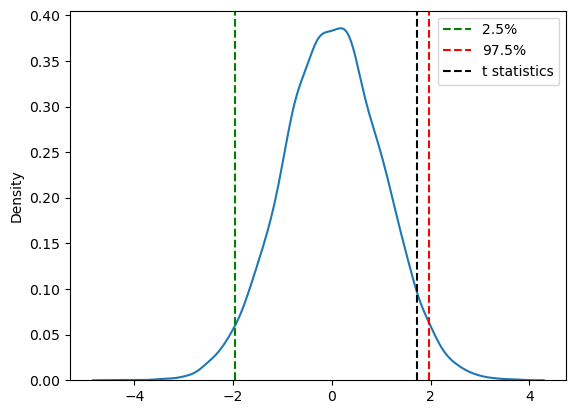

In [108]:
np.random.seed(105)
demonstration_data = np.random.standard_t(dof,10000)
sns.kdeplot(demonstration_data)
plt.axvline(t025, linestyle='--', label ='2.5%', color ='green')
plt.axvline(t975, linestyle='--', label ='97.5%', color ='red')

# plt.axvline(t95, linestyle='--', label ='95%', color ='orange')

plt.axvline(t_stat, linestyle='--', label ='t statistics', color ='black')

plt.legend()
plt.show()